In [1]:
import torch
import torch.nn.functional as F
import  matplotlib.pyplot as plt
import os
os.environ['KMP_DUPLICATE_LIB_OK']='TRUE'
%matplotlib inline

In [2]:
words = open('names.txt','r').read().splitlines()

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)

In [4]:
block_size = 3#上下文为3，输入3个字符预测下一个字符。
def build_dataset(words):
    # context length: how many characters do we take to predict the next one?
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '-->', itos[ix])
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)

    return X, Y


import random

random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [5]:
# MLP revisited
n_embd = 10  #输入样本的每一个字符映射成多少维度的嵌入向量，此处为10。
n_hidden = 200  #表示隐藏层有多少个神经元。

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/(n_embd * block_size)**0.5
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

bngain = torch.ones((1,n_hidden))
bnias = torch.zeros((1,n_hidden))
bnmean_running = torch.zeros((1,n_hidden))
bnstd_running = torch.ones((1,n_hidden))

#刚开始的损失函数图像可能呈现棒球状，开始起伏很大的过程其实是模型压缩逻辑值的过程，后面才是调整逻辑值的过程
#乘以0.1和加上0会帮助我们从一开始就避免那个过程的发生。
# parameters = [C, W1, b1, W2, b2, bngain, bnias]
parameters = [C, W1, W2, b2, bngain, bnias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

12097


tensor(-0.0070) tensor(1.0100)
tensor(-0.0001) tensor(0.9928)


(array([9.21609419e-05, 0.00000000e+00, 2.30402355e-05, 2.30402355e-05,
        9.21609419e-05, 2.53442590e-04, 3.45603532e-04, 6.22086358e-04,
        9.67689890e-04, 2.16578213e-03, 3.45603532e-03, 4.53892639e-03,
        7.18855347e-03, 1.16353189e-02, 1.85934700e-02, 2.83855701e-02,
        4.19101883e-02, 6.31993659e-02, 8.87279468e-02, 1.27619864e-01,
        1.71672794e-01, 2.29734188e-01, 2.88578949e-01, 3.47055067e-01,
        4.01890827e-01, 4.27465489e-01, 4.35160927e-01, 4.05876788e-01,
        3.59266392e-01, 2.99338739e-01, 2.40839581e-01, 1.81557055e-01,
        1.30615095e-01, 9.50870518e-02, 6.62867574e-02, 4.58961490e-02,
        2.93532600e-02, 2.00219646e-02, 1.22804455e-02, 7.76455935e-03,
        4.81540921e-03, 2.97219037e-03, 1.88929931e-03, 1.03681060e-03,
        7.37287535e-04, 4.14724238e-04, 2.99523061e-04, 9.21609419e-05,
        1.15201177e-04, 9.21609419e-05]),
 array([-5.65955019, -5.44253852, -5.22552685, -5.00851518, -4.79150351,
        -4.57449183, 

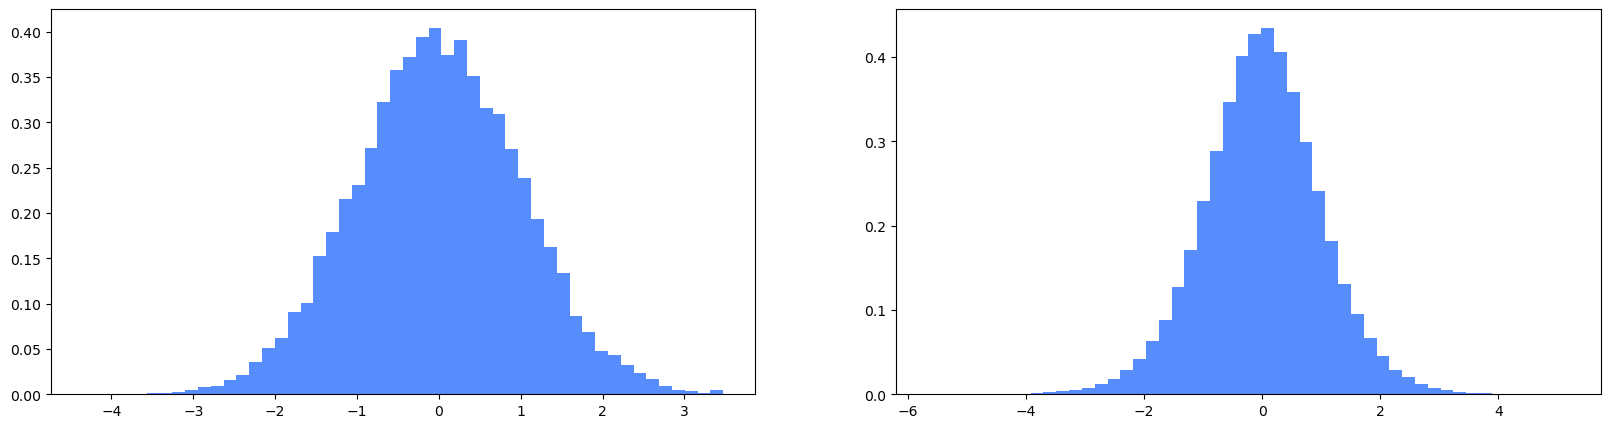

In [6]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) /10**0.5
y = x @ w#(1000, 200)

print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True)

In [34]:
hpreact.shape

torch.Size([32, 200])

In [35]:
hpreact.mean(0, keepdim=True)

tensor([[ 1.4901e-08,  7.4506e-09, -7.4506e-09, -3.3528e-08,  0.0000e+00,
         -7.4506e-09,  7.8231e-08, -1.8626e-08, -7.4506e-09, -5.5879e-09,
          5.9605e-08,  1.0990e-07,  4.0978e-08,  2.2352e-08,  6.5193e-09,
         -1.6764e-08, -1.4901e-08, -7.4506e-09,  2.9802e-08, -5.2154e-08,
         -2.2352e-08, -7.4506e-09,  4.4703e-08,  7.4506e-09, -3.7253e-09,
          3.7253e-09,  1.4901e-08, -2.9802e-08,  2.9802e-08,  2.2352e-08,
         -3.7253e-09,  0.0000e+00,  0.0000e+00, -2.2352e-08,  7.4506e-09,
         -2.1420e-08, -1.4901e-08,  1.8626e-09,  2.0489e-08, -2.2352e-08,
         -2.0489e-08, -3.7253e-08, -1.1700e-08,  1.4901e-08,  7.4506e-09,
         -3.5390e-08,  0.0000e+00,  2.9802e-08, -4.5635e-08, -3.7253e-09,
          1.6764e-08,  3.7253e-09, -2.0489e-08, -2.9802e-08, -1.6764e-08,
          4.4703e-08, -7.4506e-09,  5.4017e-08,  1.8626e-08,  1.4901e-08,
         -1.0431e-07, -1.4901e-08,  0.0000e+00, -1.8626e-08, -1.0245e-08,
          5.2154e-08, -4.4703e-08,  4.

In [36]:
hpreact.std(0, keepdim=True)

tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0

In [7]:
# same optimization as last time
max_steps = 200000#循环多少次，也就是进行多少论训练。
batch_size = 32#每个批次包含多少个样本
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)#Xtr.shape[0]表示待训练样本的总数量
    Xb, Yb = Xtr[ix], Ytr[ix]#将此次随机到的数据赋给对应变量

    # forward pass
    emb = C[Xb]  # 形状为（32，3，10）
    embcat = emb.view(emb.shape[0], -1) #需要将一次输入的样本拼接起来，按照这段代码，一次性的32个样本。
    #另一维度应该为30。
    hpreact = embcat @ W1 # + b1  # hidden layer pre-activation
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain*(hpreact - bnmeani ) / bnstdi+bnias #归一化

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    h = torch.tanh(hpreact)  # hidden layer(32,200)
    logits = h @ W2 + b2  # output layer（32，200）*（200，27）+（27，）
    loss = F.cross_entropy(logits, Yb)  # 损失函数

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.3147
  10000/ 200000: 2.1984
  20000/ 200000: 2.3375
  30000/ 200000: 2.4359
  40000/ 200000: 2.0119
  50000/ 200000: 2.2595
  60000/ 200000: 2.4775
  70000/ 200000: 2.1020
  80000/ 200000: 2.2788
  90000/ 200000: 2.1862
 100000/ 200000: 1.9474
 110000/ 200000: 2.3010
 120000/ 200000: 1.9837
 130000/ 200000: 2.4523
 140000/ 200000: 2.3839
 150000/ 200000: 2.1987
 160000/ 200000: 1.9733
 170000/ 200000: 1.8668
 180000/ 200000: 1.9973
 190000/ 200000: 1.8347


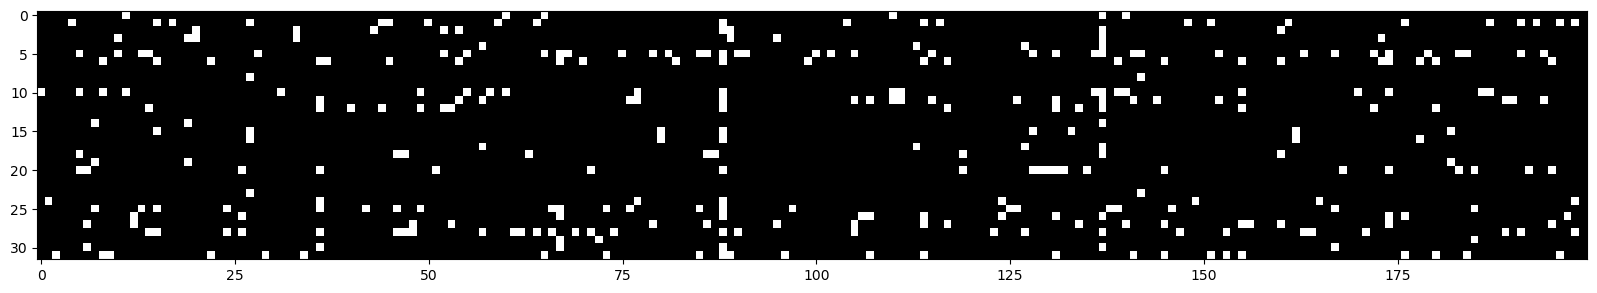

In [42]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs()>0.99,cmap='gray',interpolation='nearest')

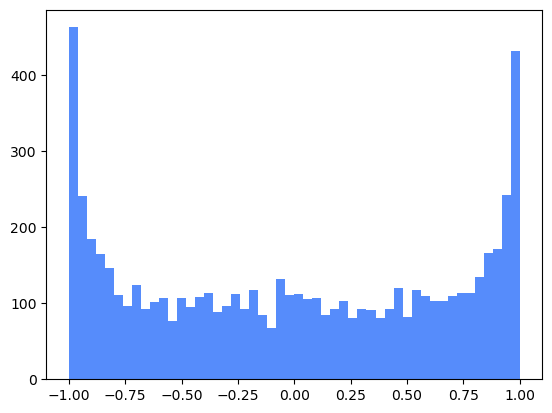

In [43]:
h.shape
plt.hist(h.view(-1).tolist(),50);#大部分值都集中在-1,1。这当然会导致logits相差过大。

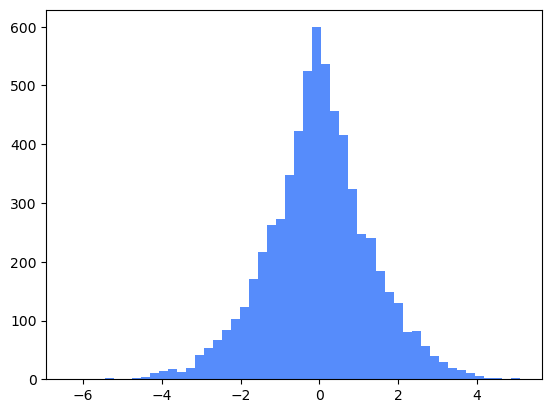

In [44]:
plt.hist(hpreact.view(-1).tolist(),50);

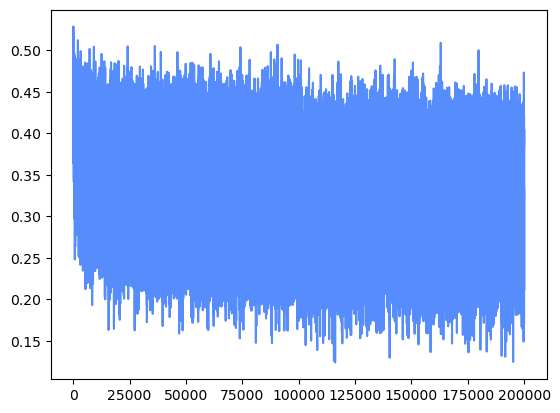

In [45]:
plt.plot(lossi)

In [46]:
# calibrate the batch norm at the end of training
with torch.no_grad():
    # pass the training set through
    emb = C[Xtr]#得到嵌入词表
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    # measure the mean/std over the entire training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

In [47]:
@torch.no_grad()  # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]

    emb = C[x]  # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1)  # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1
    # hpreact = bngain*(hpreact - hpreact.mean(0, keepdim=True) )/hpreact.std(0, keepdim=True)+bnias
    hpreact = bngain*(hpreact - bnmean_running )/bnstd_running+bnias
    h = torch.tanh(hpreact)  # (N, n_hidden)
    logits = h @ W2 + b2  # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.066636800765991
val 2.105013370513916


In [48]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []#预测结果的列表
    context = [0] * block_size  #上下文，初始化为[0,0,0]。也就是从...开始预测。
    while True:#执行循环，直到预测的下一个字符为结束符.为止，就可以跳出循环了。
    #forward pass the neural net
        emb = C[torch.tensor([context])]  #以[0,0,0]为例，会取出[C[0],C[0],C[0]],也就是（1，3，10）。
        # (1,block_size,n_embd)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))  #将所有预测结果的数字编码转换为对应的字符，然后拼接成一个完整的单词。

briangmyazziyes.
bdulyah.
briyas.
brdrner.
sherkodrlithlyllsenleigh.
santhannchyziohmkrrnn.
shdumrishimnest.
jadestly.
prgbdulfuubdgghder.
jaquezmashburjahsis.
dashby.
sadya.
sus.
zakquslutel.
subristia.
sumprrdnn.
quloeonandphillsamreyxa.
hunton.
bdasirfalvinnwrllwildtalfr.
tandysestss.


In [49]:
# 4-dimensional example of the issue
logits = torch.tensor([-5, 0.0, 0.0, 5])#假设某个模型输出层输出4个0。
probs = torch.softmax(logits, dim=0)#经过激活函数softmax。
loss = -probs[2].log()#假设正确标签为2，所以此时求2的负对数似然
probs, loss
#如果初始值相差过大，会导致损失函数过大。因此我们希望初始的时候，输出的logits之间的差距不要过大。

(tensor([4.4794e-05, 6.6481e-03, 6.6481e-03, 9.8666e-01]), tensor(5.0134))

In [50]:
##### pytorch实现

In [34]:
# Let's train a deeper network

class Linear:#线性层

    def __init__(self, fan_in, fan_out, bias=True):#输入特征数、输出特征数、是否使用偏置项
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:#批量归一化层

    def __init__(self, dim, eps=1e-5, momentum=0.1):#eps用于极小值运算，momentum用于追踪滑动均值和滑动方差的动量值
        self.eps = eps
        self.momentum = momentum
        self.training = True#是使用训练模式还是评估模式，训练模式会使用当前批次的均值和标准差，如果是评估模式，则会使用滑动均值和滑动标准差

        # parameters (trained with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

        # buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdim=True)  # batch mean
            xvar = x.var(0, keepdim=True, unbiased=True)  # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var

        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)  # normalize to unit variance
        self.out = self.gamma * xhat + self.beta

        # update the buffers
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar

        return self.out
    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

In [35]:
n_embd = 10  #每个字符对应的嵌入向量维度
n_hidden = 100  #隐藏层神经元数量，这里每个隐藏层均为100个
g = torch.Generator().manual_seed(2147483647)  # for reproducibility

C = torch.randn((vocab_size, n_embd), generator=g) #创建字符嵌入矩阵，每个字符对应一个随机初始化的10维向量

layers = [
    Linear(n_embd * block_size, n_hidden),BatchNorm1d(n_hidden), Tanh(),
    Linear(             n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(             n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(             n_hidden, n_hidden), BatchNorm1d(n_hidden),  Tanh(),
    Linear(             n_hidden, n_hidden), BatchNorm1d(n_hidden),  Tanh(),
    Linear(             n_hidden, vocab_size), BatchNorm1d(vocab_size),
]

with torch.no_grad():
    # last layer: make less confident
    layers[-1].gamma *= 0.1#缩小初始 logits 的差异，避免初始预测过度自信
    # layers[-1].weight *= 0.1#缩小初始 logits 的差异，避免初始预测过度自信

    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3#增益系数，之前Linear已经缩放过了，补偿 tanh 的信号压缩，帮助维持合理的激活尺度

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))  # number of parameters in total

for p in parameters:
    p.requires_grad = True

47551


In [36]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []
for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X,Y

    # forward pass
    emb = C[Xb]  # embed the characters into vectors
    x = emb.view(emb.shape[0], -1)  # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)  # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad()  # AFTER_DEBUG: would take out retain_graph
    for p in parameters:#保存中间结果的梯度，因为pytorch会默认保存叶子参数的梯度，不会保存中间计算结果的梯度。
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters if p.requires_grad])
    if i>= 1000:
        break# AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.2870


layer 2 (      Tanh): mean -0.00, std 0.63, saturated: 2.62%
layer 5 (      Tanh): mean +0.00, std 0.64, saturated: 2.47%
layer 8 (      Tanh): mean -0.00, std 0.64, saturated: 2.16%
layer 11 (      Tanh): mean +0.00, std 0.65, saturated: 1.81%
layer 14 (      Tanh): mean -0.00, std 0.65, saturated: 1.78%


Text(0.5, 1.0, 'activation distribution')

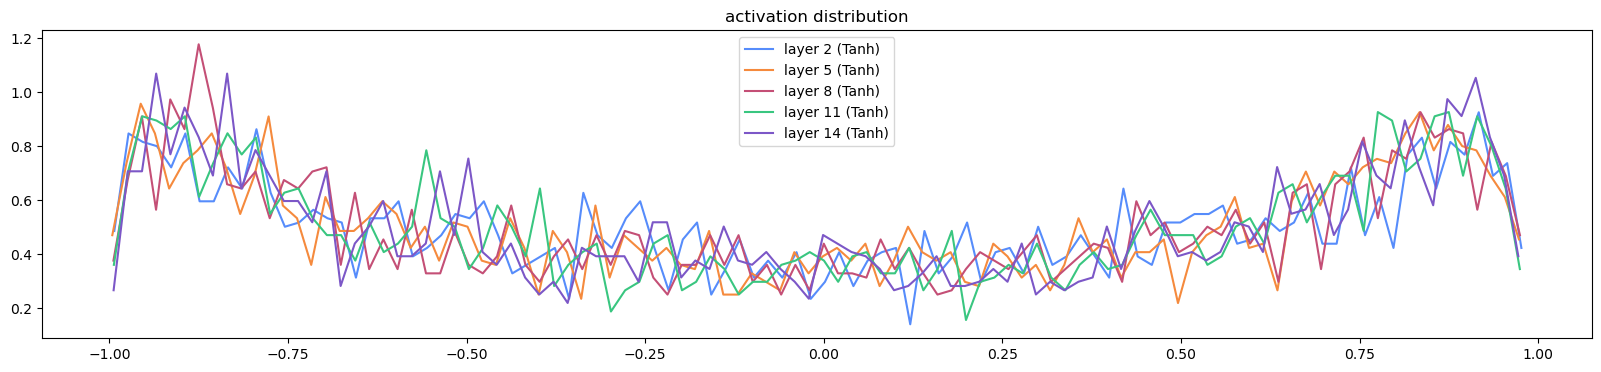

In [37]:
# visualize histograms
plt.figure(figsize=(20, 4))#创建画布，宽为20，高为4。
legends = []#创建空列表，用来保存每条曲线的图例名称。

for i, layer in enumerate(layers[:-1]):#遍历除了最后输出层以外的其他层，遍历列表时，同时返回元素索引和元素本身。
    if isinstance(layer, Tanh):#判断layer是否为Tanh的实例。
        t = layer.out#当前 Tanh 层在最近一次前向传播中产生的输出。
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' %
              (i, layer.__class__.__name__, t.mean(), t.std(),
               (t.abs() > 0.97).float().mean() * 100))#饱和百分比，可以理解为位于饱和区的数据占整体数据的比例

        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')

plt.legend(legends)
plt.title('activation distribution')

In [38]:
#观察深层神经网络中，每一个tanh激活层的输出分布，判断激活值是否过度集中、是否出现大量饱和现象。
#横坐标：Tanh 的输出值，取值范围为 \((-1,1)\)。代码将这些值划分成若干区间。
#纵坐标：落在对应区间内的概率密度，而不是直接的概率。
#\boxed{\text{区间概率}\approx\text{概率密度}\times\text{区间宽度}}

layer 2 (      Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 5 (      Tanh): mean -0.00, std 0.00, saturated: 0.00%
layer 8 (      Tanh): mean -0.00, std 0.00, saturated: 0.00%
layer 11 (      Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 14 (      Tanh): mean +0.00, std 0.00, saturated: 0.00%


Text(0.5, 1.0, 'activation distribution')

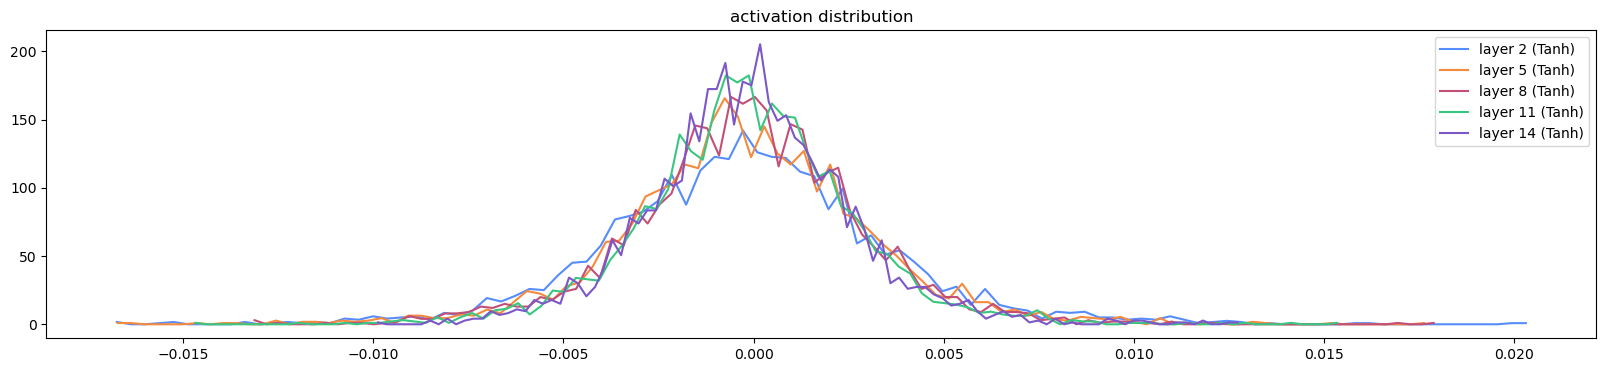

In [39]:
# visualize histograms
plt.figure(figsize=(20, 4))#创建画布，宽为20，高为4。
legends = []#创建空列表，用来保存每条曲线的图例名称。

for i, layer in enumerate(layers[:-1]):#遍历除了最后输出层以外的其他层，遍历列表时，同时返回元素索引和元素本身。
    if isinstance(layer, Tanh):#判断layer是否为Tanh的实例。
        t = layer.out.grad#当前 Tanh 层在最近一次前向传播中产生的输出。
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' %
              (i, layer.__class__.__name__, t.mean(), t.std(),
               (t.abs() > 0.97).float().mean() * 100))#饱和百分比，可以理解为位于饱和区的数据占整体数据的比例

        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')

plt.legend(legends)
plt.title('activation distribution')

weight   (27, 10) | mean -0.000000 | std 1.019888e-02 | grad:data ratio 1.018849e-02
weight  (30, 100) | mean +0.000092 | std 8.238437e-03 | grad:data ratio 2.635841e-02
weight (100, 100) | mean +0.000031 | std 7.318118e-03 | grad:data ratio 4.377148e-02
weight (100, 100) | mean -0.000019 | std 6.662027e-03 | grad:data ratio 3.949898e-02
weight (100, 100) | mean -0.000019 | std 5.821519e-03 | grad:data ratio 3.468163e-02
weight (100, 100) | mean +0.000053 | std 5.445300e-03 | grad:data ratio 3.243370e-02
weight  (100, 27) | mean -0.000165 | std 1.046846e-02 | grad:data ratio 6.281270e-02


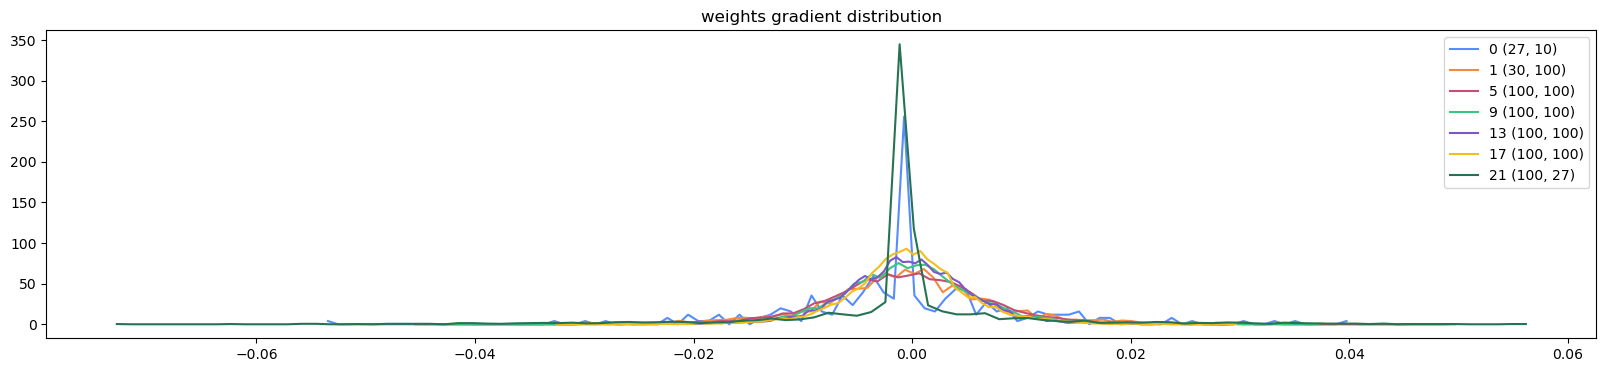

In [40]:
# visualize histograms
plt.figure(figsize=(20, 4))  # width and height of the plot
legends = []

for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2:#只分析C和W，因为偏置为一维，不参与分析
        print('weight %10s | mean %+f | std %e | grad:data ratio %e' %
              (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))

        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'{i} {tuple(p.shape)}')

plt.legend(legends)
plt.title('weights gradient distribution');

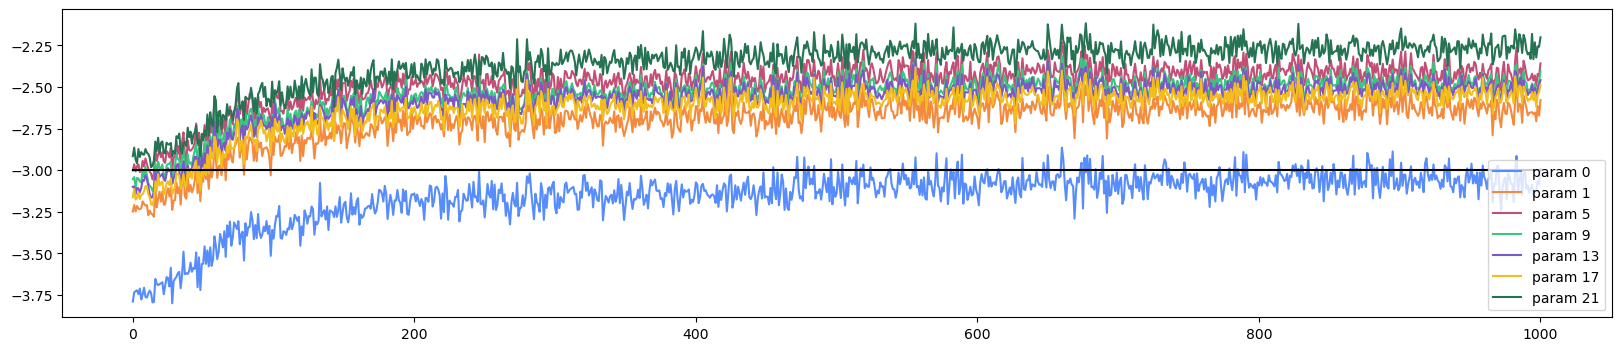

In [41]:
plt.figure(figsize=(20, 4))
legends = []

for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('param %d' % i)

plt.plot([0, len(ud)], [-3, -3], 'k')  # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);